# Is our AI spend paying off? A cost and ROI review for Northwind Insurance

The CFO has asked a simple question: *we spent about £37k on model usage this year; what did we get for it?* Each team's lead says their tools save "hours a week". This notebook works through the review the way I would at work: start with where the money goes, then tie spend to the outcome each team exists to produce, then check the time-saved claims against evidence, and finish with where money can be saved.

The data is synthetic (Northwind is fictional) but structured like a real model gateway's billing export: one row per team, feature, model and day, plus weekly outcome counts, a randomised pilot and a staff survey.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tokenroi import roi
from tokenroi.warehouse import connect

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200)
con = connect()
usage = pd.read_sql("SELECT * FROM v_usage", con, parse_dates=["date"])
print(f"{len(usage):,} daily rows, {usage['date'].min():%d %b} to {usage['date'].max():%d %b %Y}, "
      f"£{usage['cost_gbp'].sum():,.0f} total, {usage['requests'].sum():,} requests")
usage.head()

2,457 daily rows, 01 Jan to 30 Sep 2026, £37,800 total, 1,367,587 requests


,date,month,team,feature,model_tier,requests,failed_requests,attempts,input_tokens,cached_input_tokens,output_tokens,cost_gbp,failed_attempt_cost_gbp
0,2026-01-01,2026-01,Customer Support,Ticket reply drafting,medium,79,2,81,300397,0,8444,0.4111,0.010151
1,2026-01-02,2026-01,Customer Support,Ticket reply drafting,medium,1787,32,1819,5999140,0,947231,12.8824,0.226628
2,2026-01-03,2026-01,Customer Support,Ticket reply drafting,medium,84,1,85,309530,0,16436,0.4701,0.005531
3,2026-01-04,2026-01,Customer Support,Ticket reply drafting,medium,101,1,102,487708,0,59065,0.9396,0.009212
4,2026-01-05,2026-01,Customer Support,Ticket reply drafting,medium,2582,46,2628,9969797,0,982452,17.8585,0.312592


## 1. Where does the money go?

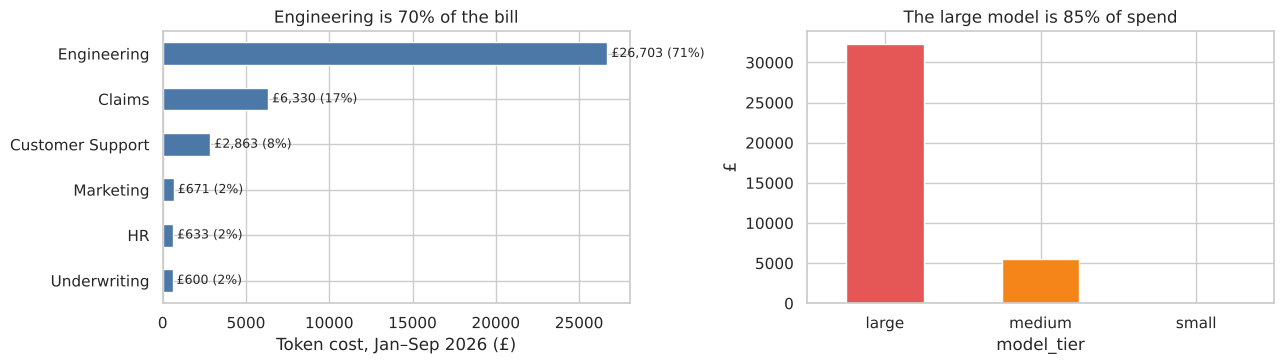

In [2]:
by_team = usage.groupby("team")["cost_gbp"].sum().sort_values()
by_model = usage.groupby("model_tier")["cost_gbp"].sum().reindex(["large", "medium", "small"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
by_team.plot.barh(ax=axes[0], color="#4C78A8"); axes[0].set_xlabel("Token cost, Jan–Sep 2026 (£)")
for i, v in enumerate(by_team):
    axes[0].text(v, i, f" £{v:,.0f} ({v / by_team.sum():.0%})", va="center", fontsize=9)
axes[0].set_title("Engineering is 70% of the bill"); axes[0].set_ylabel("")
by_model.plot.bar(ax=axes[1], rot=0, color=["#E45756", "#F58518", "#54A24B"])
axes[1].set_ylabel("£"); axes[1].set_title(f"The large model is {by_model['large'] / by_model.sum():.0%} of spend")
plt.tight_layout()

Spend is very concentrated. Engineering's coding assistant is 70% of the bill, and Claims is most of the rest. Customer Support makes more requests than anyone (half a million) but costs little, because it uses the medium model. The large model takes 85% of spend, so **which model each task uses** is the biggest cost lever, before anyone writes a shorter prompt.

### Over time

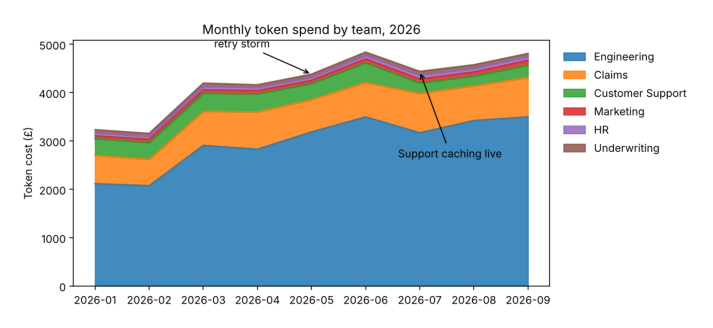

In [3]:
fig = plt.figure(figsize=(10, 4)); plt.imshow(plt.imread("reports/figures/spend_by_team.png")); plt.axis("off");

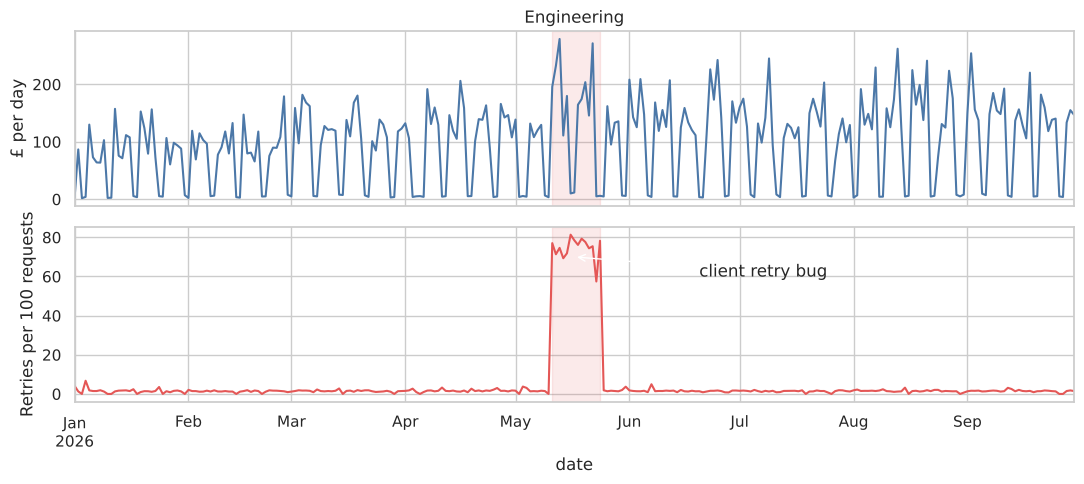

In [4]:
daily = usage[usage["team"] == "Engineering"].groupby("date")[["cost_gbp", "requests", "attempts"]].sum()
daily["retries_per_100_requests"] = 100 * (daily["attempts"] - daily["requests"]) / daily["requests"].clip(lower=1)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
daily["cost_gbp"].plot(ax=axes[0], color="#4C78A8"); axes[0].set_ylabel("£ per day"); axes[0].set_title("Engineering")
daily["retries_per_100_requests"].plot(ax=axes[1], color="#E45756"); axes[1].set_ylabel("Retries per 100 requests")
for ax in axes:
    ax.axvspan("2026-05-11", "2026-05-24", color="#E45756", alpha=0.12)
axes[1].annotate("client retry bug", xy=(pd.Timestamp("2026-05-17"), 70), xytext=(pd.Timestamp("2026-06-20"), 60),
                 arrowprops={"arrowstyle": "->"})
plt.tight_layout()

The daily view shows what the monthly chart hides: for two weeks in May, Engineering's retries jumped from under 2 to about 75 per 100 requests. A client bug was retrying every failure three times, and every attempt is billed. In a monthly report it looks like ordinary growth. **A daily alert on retries per request would have caught it on day one.**

The other visible event is July, when Customer Support switched on prompt caching for its 3,000-token system prompt:

In [5]:
pd.read_sql(open("sql/04_caching_before_after.sql").read(), con)

,period,cost_per_1k_requests_gbp,input_tokens_cached_pct
0,before caching,7.014,0.0
1,after caching,3.693,69.5


Cost per request almost halved overnight, with no change to the product. That is the cheapest optimisation there is, and Support is the only team using it.

## 2. Cost per outcome

Token spend means nothing until it is divided by what the team produced. Each team has one outcome it is measured on.

In [6]:
unit = pd.read_sql(open("sql/02_unit_cost_q3.sql").read(), con)
unit.merge(pd.read_sql("SELECT team, outcome_unit FROM dim_team", con))

,team,token_cost_gbp,ai_assisted_outcomes,token_cost_per_outcome_gbp,outcome_unit
0,Engineering,10089.94,1242,8.1239,pull request merged
1,Marketing,262.75,211,1.2453,campaign asset approved
2,Claims,2344.27,5918,0.3961,claim processed
3,HR,234.06,1025,0.2284,employee query answered
4,Underwriting,217.97,2091,0.1042,quote issued
5,Customer Support,678.98,30898,0.0220,ticket resolved


Q3 2026 token cost per AI-assisted outcome ranges from **2p per ticket resolved** in Customer Support to **£8.12 per pull request merged** in Engineering. Those are not comparable on their own; a merged pull request is worth far more than a ticket reply. The comparison only makes sense once each outcome is valued, which needs the time saved.

## 3. How much time does AI really save?

Team leads gave self-reported figures in a survey. Customer Support and Claims also ran a randomised pilot in February and March: items were randomly handled with or without AI, and handle time was logged.

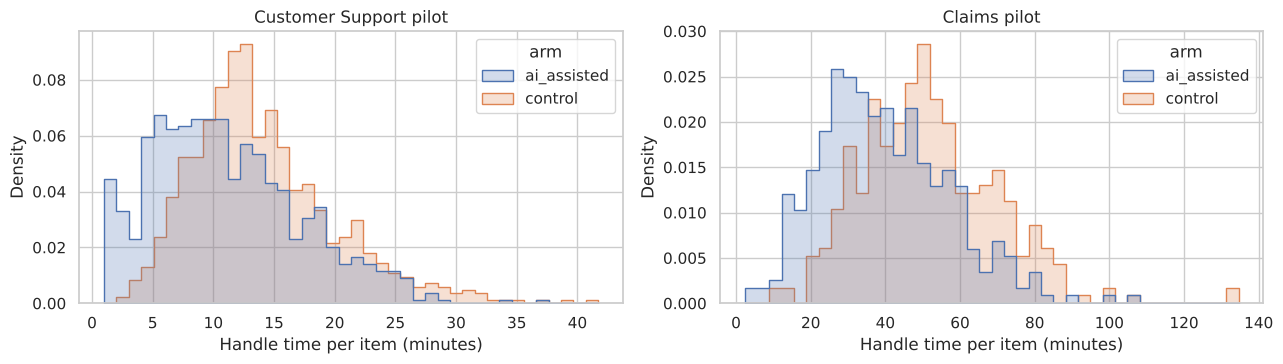

,team_id,minutes_saved,ci_low,ci_high,n_control,n_ai,team
0,1,2.94,2.35,3.54,826,774,Customer Support
1,2,11.96,9.24,14.60,349,351,Claims


In [7]:
pilot = pd.read_sql("SELECT * FROM pilot_items", con)
teams = pd.read_sql("SELECT team_id, team FROM dim_team", con)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (tid, g) in zip(axes, pilot.merge(teams).groupby("team_id")):
    sns.histplot(data=g, x="handle_minutes", hue="arm", bins=40, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{g['team'].iloc[0]} pilot"); ax.set_xlabel("Handle time per item (minutes)")
plt.tight_layout()
fx = roi.pilot_effect(pilot).merge(teams)
fx.round(2)

In [8]:
survey = pd.read_sql("SELECT * FROM survey_time_saved", con).merge(teams)
cmp = survey.merge(fx[["team_id", "minutes_saved", "ci_low", "ci_high"]], how="left")
cmp["survey_vs_pilot"] = cmp["self_reported_minutes_saved"] / cmp["minutes_saved"]
cmp[["team", "self_reported_minutes_saved", "respondents", "minutes_saved", "ci_low", "ci_high", "survey_vs_pilot"]].round(2)

,team,self_reported_minutes_saved,respondents,minutes_saved,ci_low,ci_high,survey_vs_pilot
0,Customer Support,6.5,41,2.94,2.35,3.54,2.21
1,Claims,20.9,22,11.96,9.24,14.60,1.75
2,Engineering,87.4,31,NaN,NaN,NaN,NaN
3,Underwriting,10.8,14,NaN,NaN,NaN,NaN
4,Marketing,23.4,10,NaN,NaN,NaN,NaN
5,HR,6.8,5,NaN,NaN,NaN,NaN


This is the most important finding in the review. **Where we can check, staff report about twice the time saving that the pilot measures** (Support: 6.5 self-reported vs 2.9 measured minutes; Claims: 20.9 vs 12.0). That is not dishonesty; people remember the tasks where the tool helped a lot, and they don't time anything.

So for the four teams without a pilot, I scale the survey figure by the ratio seen in the pilot teams (0.51) and widen the uncertainty, rather than taking the survey at face value. The better fix is to run a two-week pilot in Engineering, the biggest spender.

## 4. Return on investment

Value = minutes saved × the team's loaded hourly cost × AI-assisted outcomes. Cost = tokens plus the platform team's cost (gateway, monitoring, on-call), allocated by request share. That second part matters:

In [9]:
r = json.loads(open("reports/metrics.json").read())
pd.Series(r["totals"])

token_cost_gbp                    13827.970
platform_cost_gbp                 18000.000
total_cost_gbp                    31827.970
value_gbp                        152721.070
value_if_survey_believed_gbp     301057.110
hours_saved                        3913.000
roi                                   3.798
token_share_of_total_cost_pct        43.400
dtype: float64

**Tokens are only 43% of the total cost.** The platform team costs more than the API bill, so a review that only looks at token spend overstates ROI and misses the biggest fixed cost.

In [10]:
t = pd.DataFrame(r["teams"]).set_index("team")
t[["outcome_unit", "total_cost_per_outcome_gbp", "minutes_saved", "method", "value_per_outcome_gbp", "roi", "roi_low", "roi_high",
   "roi_if_survey_believed"]].round(2)

,outcome_unit,total_cost_per_outcome_gbp,minutes_saved,method,value_per_outcome_gbp,roi,roi_low,roi_high,roi_if_survey_believed
team,,,,,,,,,
Claims,claim processed,0.61,11.96,randomised pilot,6.78,10.06,7.55,12.51,18.34
Underwriting,quote issued,0.62,5.53,survey x pilot haircut,4.42,6.17,3.93,8.42,13.01
Customer Support,ticket resolved,0.23,2.94,randomised pilot,1.37,5.06,3.85,6.31,12.42
Engineering,pull request merged,14.18,44.75,survey x pilot haircut,46.24,2.26,1.24,3.28,5.37
HR,employee query answered,0.93,3.48,survey x pilot haircut,1.86,1.00,0.37,1.62,2.90
Marketing,campaign asset approved,6.45,11.98,survey x pilot haircut,7.99,0.24,-0.15,0.63,1.42


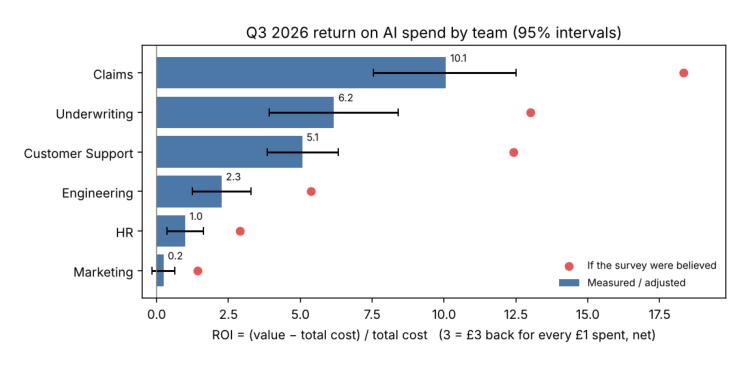

In [11]:
fig = plt.figure(figsize=(10, 4.5)); plt.imshow(plt.imread("reports/figures/roi_by_team.png")); plt.axis("off");

- **Overall, every £1 spent returned about £4.80 in staff time** (ROI 3.8 net). Believing the survey would have doubled that, which is exactly the kind of number that gets a budget approved and then cannot be found in the P&L.
- **Claims is the stand-out (ROI 10):** long documents, expensive staff and a measured 12-minute saving per claim.
- **Engineering has the largest value in pounds** but a modest ROI (2.3), because it uses the most expensive model at the highest volume.
- **Marketing does not clearly pay for itself.** ROI 0.2, and the interval includes a loss. It uses the large model for short copy and approves few assets.

## 5. Where can we save money without losing quality?

Two levers, both checked against an offline quality evaluation (reviewers' acceptance rate per feature and model):

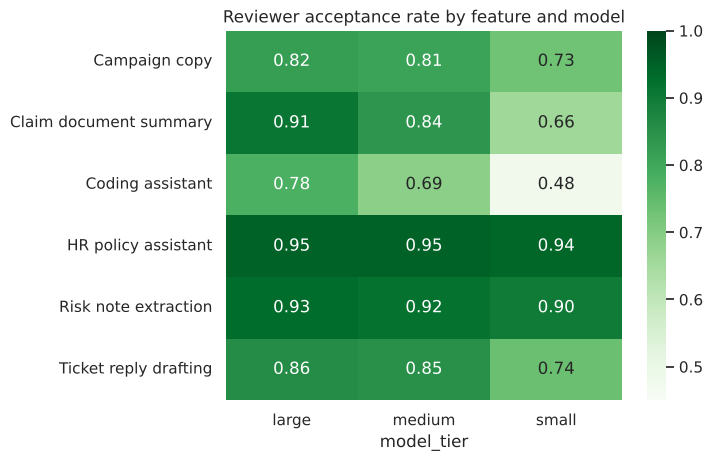

In [12]:
q = pd.read_sql("SELECT * FROM model_quality", con).pivot(index="feature", columns="model_tier", values="acceptance_rate")
sns.heatmap(q[["large", "medium", "small"]], annot=True, fmt=".2f", cmap="Greens", vmin=0.45, vmax=1)
plt.title("Reviewer acceptance rate by feature and model"); plt.ylabel("");

Some tasks barely care which model does them (HR policy answers: 95% on the large model, 94% on the small one, which costs about 16 times less per output token), while the coding assistant falls from 78% to 48% on the small model. So routing has to be decided per feature. I allow a switch only when acceptance drops by no more than 2 points.

In [13]:
s = r["savings"]
pd.DataFrame(s["routing_decisions"])

,feature,from,to,quality_from,quality_to
0,Campaign copy,large,medium,0.82,0.81
1,HR policy assistant,large,small,0.95,0.94
2,Risk note extraction,medium,small,0.92,0.90


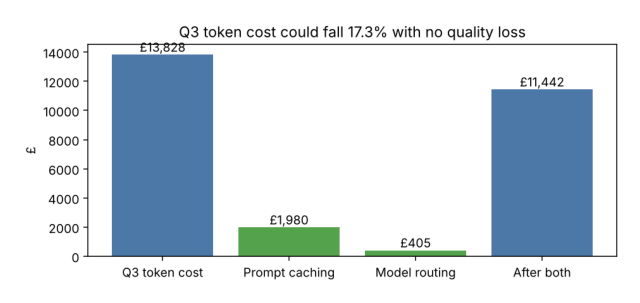

q3_token_cost_gbp              13827.97
caching_saving_gbp              1980.18
routing_saving_gbp               405.41
q3_cost_after_both_gbp         11442.38
saving_pct                        17.30
retry_storm_excess_cost_gbp      835.21
dtype: float64

In [14]:
fig = plt.figure(figsize=(8, 3.8)); plt.imshow(plt.imread("reports/figures/savings.png")); plt.axis("off");
pd.Series({k: v for k, v in s.items() if not isinstance(v, (dict, list))})

## Recommendations

1. **Turn on prompt caching for the coding assistant now.** It is worth about £1,700 a quarter on its own, and Support has already proved it works.
2. **Route HR, campaign copy and risk-note extraction to cheaper models.** It saves about £400 a quarter with at most a 2-point quality drop; small money, but zero effort.
3. **Alert on retries per request, daily.** The May bug cost £835 and nobody noticed.
4. **Put Marketing on probation.** Move it to the medium model and re-measure next quarter; if ROI is still not clearly positive, stop.
5. **Run a two-week randomised pilot in Engineering** before approving its budget increase. It is the largest spend and its time saving is the least certain.
6. **Report ROI on total cost of ownership,** with intervals, and never on survey figures alone.